<a href="https://colab.research.google.com/github/mlewis26/eeg-alpha-eyes-open-closed/blob/main/eeg-alpha-eye-open-closed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install mne

import mne
from mne.datasets import eegbci

mne.set_log_level("WARNING")  # keeps the output quiet

data = {}

for subj in range(1, 11):
    files = eegbci.load_data(subj, runs=[1, 2])  # run 1 = eyes open, run 2 = eyes closed
    raws = []
    for f in files:
        raw = mne.io.read_raw_edf(f, preload=True)
        eegbci.standardize(raw)   # fixes the channel names
        raw.filter(1., 40.)       # keep 1-40 Hz
        raws.append(raw)
    data[subj] = {"open": raws[0], "closed": raws[1]}
    print("Loaded subject", subj)

Loaded subject 1
Loaded subject 2
Loaded subject 3
Loaded subject 4
Loaded subject 5
Loaded subject 6
Loaded subject 7
Loaded subject 8
Loaded subject 9


Failed to download 'S010R01.edf'. Will attempt the download again 2 more times.
Failed to download 'S010R01.edf'. Will attempt the download again 1 more time.


HTTPError: 502 Server Error: Bad Gateway for url: https://physionet.org/files/eegmmidb/1.0.0/S010/S010R01.edf

In [3]:
subj = 10
files = eegbci.load_data(subj, runs=[1, 2])
raws = []
for f in files:
    raw = mne.io.read_raw_edf(f, preload=True)
    eegbci.standardize(raw)
    raw.filter(1., 40.)
    raws.append(raw)
data[subj] = {"open": raws[0], "closed": raws[1]}
print("Loaded subject", subj, "| subjects loaded:", len(data))


Failed to download 'S010R01.edf'. Will attempt the download again 2 more times.


Loaded subject 10 | subjects loaded: 10


In [ ]:
import numpy as np

occipital = ["O1", "Oz", "O2"]   # back-of-head channels, where alpha is strongest
alpha_open, alpha_closed = [], []

for subj in range(1, 11):
    for cond, store in [("open", alpha_open), ("closed", alpha_closed)]:
        raw = data[subj][cond]
        psd = raw.compute_psd(fmin=8, fmax=12, picks=occipital)
        power, freqs = psd.get_data(return_freqs=True)
        store.append(power.mean() * 1e12)   # convert to µV²/Hz

alpha_open = np.array(alpha_open)
alpha_closed = np.array(alpha_closed)

for i in range(10):
    print(f"Subject {i+1}: open = {alpha_open[i]:.2f}, closed = {alpha_closed[i]:.2f}")

Subject 1: open = 45.24, closed = 717.60
Subject 2: open = 21.46, closed = 246.78
Subject 3: open = 36.99, closed = 722.54
Subject 4: open = 3.68, closed = 106.14
Subject 5: open = 5.17, closed = 8.08
Subject 6: open = 3.45, closed = 3.66
Subject 7: open = 77.00, closed = 470.04
Subject 8: open = 8.04, closed = 52.63
Subject 9: open = 21.35, closed = 69.35
Subject 10: open = 36.59, closed = 510.88


In [ ]:
from scipy import stats

t, p = stats.ttest_rel(alpha_closed, alpha_open)   # paired t-test
print(f"Mean alpha, eyes open:   {alpha_open.mean():.2f} µV²/Hz")
print(f"Mean alpha, eyes closed: {alpha_closed.mean():.2f} µV²/Hz")
print(f"Paired t-test: t = {t:.2f}, p = {p:.4f}")

Mean alpha, eyes open:   25.90 µV²/Hz
Mean alpha, eyes closed: 290.77 µV²/Hz
Paired t-test: t = 3.08, p = 0.0131


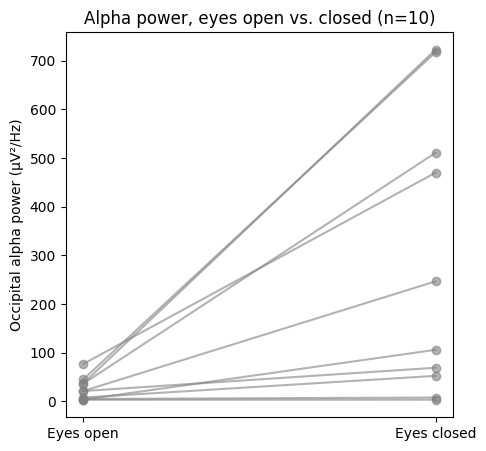

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 5))
for o, c in zip(alpha_open, alpha_closed):
    ax.plot(["Eyes open", "Eyes closed"], [o, c], "-o", color="gray", alpha=0.6)
ax.set_ylabel("Occipital alpha power (µV²/Hz)")
ax.set_title("Alpha power, eyes open vs. closed (n=10)")
plt.show()

In [ ]:
log_open = np.log10(alpha_open)
log_closed = np.log10(alpha_closed)
t, p = stats.ttest_rel(log_closed, log_open)
print(f"Log-transformed paired t-test: t = {t:.2f}, p = {p:.4f}")

Log-transformed paired t-test: t = 5.62, p = 0.0003


In [ ]:
print((alpha_closed > alpha_open).sum(), "of 10 subjects had higher alpha with eyes closed")

10 of 10 subjects had higher alpha with eyes closed


In [ ]:
print(data[1]["open"].ch_names)

['FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'Fp1', 'Fpz', 'Fp2', 'AF7', 'AF3', 'AFz', 'AF4', 'AF8', 'F7', 'F5', 'F3', 'F1', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT7', 'FT8', 'T7', 'T8', 'T9', 'T10', 'TP7', 'TP8', 'P7', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2', 'Iz']


In [ ]:
central = ["Cz"]
theta_open, theta_closed = [], []

for subj in range(1, 11):
    for cond, store in [("open", theta_open), ("closed", theta_closed)]:
        raw = data[subj][cond]
        psd = raw.compute_psd(fmin=4, fmax=8, picks=central)
        power, freqs = psd.get_data(return_freqs=True)
        store.append(power.mean() * 1e12)

theta_open = np.array(theta_open)
theta_closed = np.array(theta_closed)

print(theta_open.mean(), theta_closed.mean())

44.099463647038945 46.00405963612266


In [ ]:
central = ["Cz"]
beta_open, beta_closed = [],[]

for subj in range(1, 11):
  for cond, store in [("open", beta_open), ("closed", beta_closed)]:
    raw = data[subj][cond]
    psd = raw.compute_psd(fmin=13, fmax=30, picks=central)
    power, freqs = psd.get_data(return_freqs=True)
    store.append(power.mean() * 1e12)

beta_open = np.array(beta_open)
beta_closed = np.array(beta_closed)

print(beta_open.mean(), beta_closed.mean())

6.203187807705275 8.618642086991926


In [ ]:
print((beta_closed > beta_open).sum(), "of 10 subjects had higher beta with eyes closed")

10 of 10 subjects had higher beta with eyes closed


In [ ]:
central = ["Cz"]
theta_open, theta_closed = [], []
beta_open, beta_closed = [], []

for subj in range(1, 11):
    for cond, t_store, b_store in [("open", theta_open, beta_open), ("closed", theta_closed, beta_closed)]:
        raw = data[subj][cond]
        t_psd = raw.compute_psd(fmin=4, fmax=8, picks=central)
        b_psd = raw.compute_psd(fmin=13, fmax=30, picks=central)
        t_store.append(t_psd.get_data().mean() * 1e12)
        b_store.append(b_psd.get_data().mean() * 1e12)

theta_open = np.array(theta_open)
theta_closed = np.array(theta_closed)
beta_open = np.array(beta_open)
beta_closed = np.array(beta_closed)

print(len(theta_open), len(beta_open))

10 10


In [ ]:
ratio_open = theta_open / beta_open
ratio_closed = theta_closed / beta_closed
print(ratio_open.mean(), ratio_closed.mean())

7.229943261162466 5.883824544490929


In [4]:
print(len(data))

10


In [6]:
import numpy as np

central = ["Cz"]
theta_open, theta_closed = [], []
beta_open, beta_closed = [], []

for subj in range(1, 11):
    for cond, t_store, b_store in [("open", theta_open, beta_open), ("closed", theta_closed, beta_closed)]:
        raw = data[subj][cond]
        t_psd = raw.compute_psd(fmin=4, fmax=8, picks=central)
        b_psd = raw.compute_psd(fmin=13, fmax=30, picks=central)
        t_store.append(t_psd.get_data().mean() * 1e12)
        b_store.append(b_psd.get_data().mean() * 1e12)

theta_open = np.array(theta_open)
theta_closed = np.array(theta_closed)
beta_open = np.array(beta_open)
beta_closed = np.array(beta_closed)

print(len(theta_open), len(beta_open))

10 10


Mean ratio, eyes open:   7.23
Mean ratio, eyes closed: 5.88
8 of 10 subjects had a higher ratio with eyes open
Ratio, raw: t = -1.43, p = 0.1858
Ratio, log: t = -1.90, p = 0.0905
Theta, log: t = 0.46, p = 0.6556
Beta, log: t = 3.84, p = 0.0040


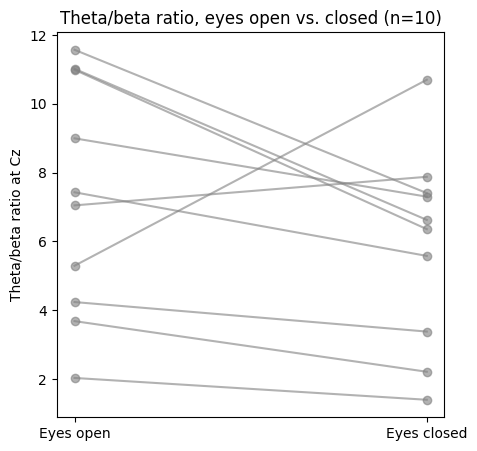

In [7]:
from scipy import stats
import matplotlib.pyplot as plt

ratio_open = theta_open / beta_open
ratio_closed = theta_closed / beta_closed

print(f"Mean ratio, eyes open:   {ratio_open.mean():.2f}")
print(f"Mean ratio, eyes closed: {ratio_closed.mean():.2f}")
print((ratio_open > ratio_closed).sum(), "of 10 subjects had a higher ratio with eyes open")

# All tests are closed minus open. A negative t means open was higher.
t, p = stats.ttest_rel(ratio_closed, ratio_open)
print(f"Ratio, raw: t = {t:.2f}, p = {p:.4f}")

t, p = stats.ttest_rel(np.log10(ratio_closed), np.log10(ratio_open))
print(f"Ratio, log: t = {t:.2f}, p = {p:.4f}")

t, p = stats.ttest_rel(np.log10(theta_closed), np.log10(theta_open))
print(f"Theta, log: t = {t:.2f}, p = {p:.4f}")

t, p = stats.ttest_rel(np.log10(beta_closed), np.log10(beta_open))
print(f"Beta, log: t = {t:.2f}, p = {p:.4f}")

fig, ax = plt.subplots(figsize=(5, 5))
for o, c in zip(ratio_open, ratio_closed):
    ax.plot(["Eyes open", "Eyes closed"], [o, c], "-o", color="gray", alpha=0.6)
ax.set_ylabel("Theta/beta ratio at Cz")
ax.set_title("Theta/beta ratio, eyes open vs. closed (n=10)")
plt.show()